# DEL 1 :Grundläggande analys och statistik

### 1.1. Import och datainläsning

In [172]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats



### 1.2. Datainläsning

In [173]:
df = pd.read_csv("../data/health_study_dataset (1).csv")

### 1.3. Basvärde

In [174]:
bp_values = df["systolic_bp"].dropna()
bp_count = len(bp_values)
bp_mean = bp_values.mean()
bp_std = bp_values.std(ddof=1)
bp_se = bp_std / np.sqrt(bp_count)


### 1.4. Konstanter

In [175]:
RANDOM_SEED = 42
ALPHA = 0.05
BP_COLUMN = "systolic_bp"
SEX_COLUMN = ["F", "M"]
SMOKER_COLUMN = ["No", "Yes"]
SIM_GROUP_SIZE = 1000
N_BOOTSTRAP = 50000
BOOTSTRAP_START = 500
BOOTSTRAP_STEP = 1000
N_POWER_SIM = 10000
POWER_SAMPLE_SIZE = [100, 200, 400, 800, 1600, 3200]

### 1.5. Färgpalett och figurstil för visualisering

In [176]:
COLORS = {
    "blood_pressure": "#1ADF8D",
    "blood_pressure_light": "#3B8055",
    "non_smoker": "#8A8029",
    "smoker": "#05565F",
    "female": "#805392",
    "male": "#478D47",
    "reference": "#AA0673",
    "ink": "#070A00",
    "muted": "#423F40",
}

SMOKING_COLORS = {"No": COLORS["non_smoker"], "Yes": COLORS["smoker"]}
SEX_colors = {"F": COLORS["female"], "M": COLORS["male"]}

### 1.6. Graf - visualisering

In [177]:
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor":  "#FFFFFF",
    "savefig.dpi": 150,

    "font.family":  "DejaVu Sans",
    "font.size": 10,
    "text.color": COLORS["ink"],
   
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.facecolor": "#FFFFFF",
    "axes.labelsize": 10,
    "axes.labelcolor": COLORS["ink"],
    "axes.edgecolor": "#9C9494",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,

    "xtick.color": COLORS["muted"],
    "ytick.color": COLORS["muted"],

    "grid.color": "#A79A9A",

    "legend.frameon": False,
})

def style_axis(axis, grid_axis="y"):
    axis.grid(axis=grid_axis, linewidth=0.8)
    axis.spines["left"].set_alpha(0.7)
    axis.spines["bottom"].set_alpha(0.7)

## 2. Översikt över datasetet

### 2.1. Datasetets struktur och datatyper

In [178]:
display(df.head(3))
display(df.tail(3))

print(f"\nDatasetet  --  -  Antal rader: {df.shape[0]}  --  Antal kolumner: {df.shape[1]}")

print(f"\n{"Kolumnamn": <20} Datatype:")
for column in df.columns:
    print(f" - {column: <15} : {df[column].dtype}")

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
797,798,60,F,175.0,49.7,146.5,5.57,No,0
798,799,50,F,172.6,55.3,155.0,3.58,No,0
799,800,50,M,189.2,79.4,139.7,5.62,No,0



Datasetet  --  -  Antal rader: 800  --  Antal kolumner: 9

Kolumnamn            Datatype:
 - id              : int64
 - age             : int64
 - sex             : str
 - height          : float64
 - weight          : float64
 - systolic_bp     : float64
 - cholesterol     : float64
 - smoker          : str
 - disease         : int64


### 2.2. Datavalidering och datarensning

In [179]:
expected_values = ({df.columns[0]: df["id"].is_unique,
                    df.columns[2]: df["sex"].isin(SEX_COLUMN).all(),
                    df.columns[7]: df["smoker"].isin(SMOKER_COLUMN).all(),
                    df.columns[8]: df["disease"].isin([0, 1]).all(),
                    })
display(pd.DataFrame(expected_values, index=["Validering"]).replace({True: "Korrekt", False: "Fel"}))

,id,sex,smoker,disease
Validering,Korrekt,Korrekt,Korrekt,Korrekt


### 2.2.1. Saknade värden i datasetet

In [180]:

display(df.isna().sum().to_frame(name="Saknade värden").T)

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Saknade värden,0,0,0,0,0,0,0,0,0


### 2.2.2. Validering av datatyper

In [181]:
expected_types = {
    "id": "int", 
    "age": "int", 
    "sex": "str", 
    "height": "float",
    "weight": "float",
    "systolic_bp": "float",
    "cholesterol": "float",
    "smoker": "str",
    "disease": "int"
    }


correct_columns = []
incorrect_columns = []


for column in df.columns:
    expected_type = expected_types[column]
    passed = True
    
    for value in df[column]:
        actual_type = type(value).__name__
        if actual_type != expected_type:
            passed = False
    if passed:
        correct_columns.append(column)
    else:
        incorrect_columns.append(column)

result = {column: "Korrekt" if column in correct_columns else "Fel" for column in df.columns}

display(pd.DataFrame(result, index=["Datatyp validering"]))

,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
Datatyp validering,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt,Korrekt


## 3. Beskrivande analys för datasetet

### 3.1. Beskrivande statistik för datasetet

In [182]:
calculate_columns = df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(["mean", "median", "min", "max"])

display(calculate_columns.round(2))

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


### 3.2. Visualisering

#### 3.2.1 Fördelning av systoliskt blodtryck

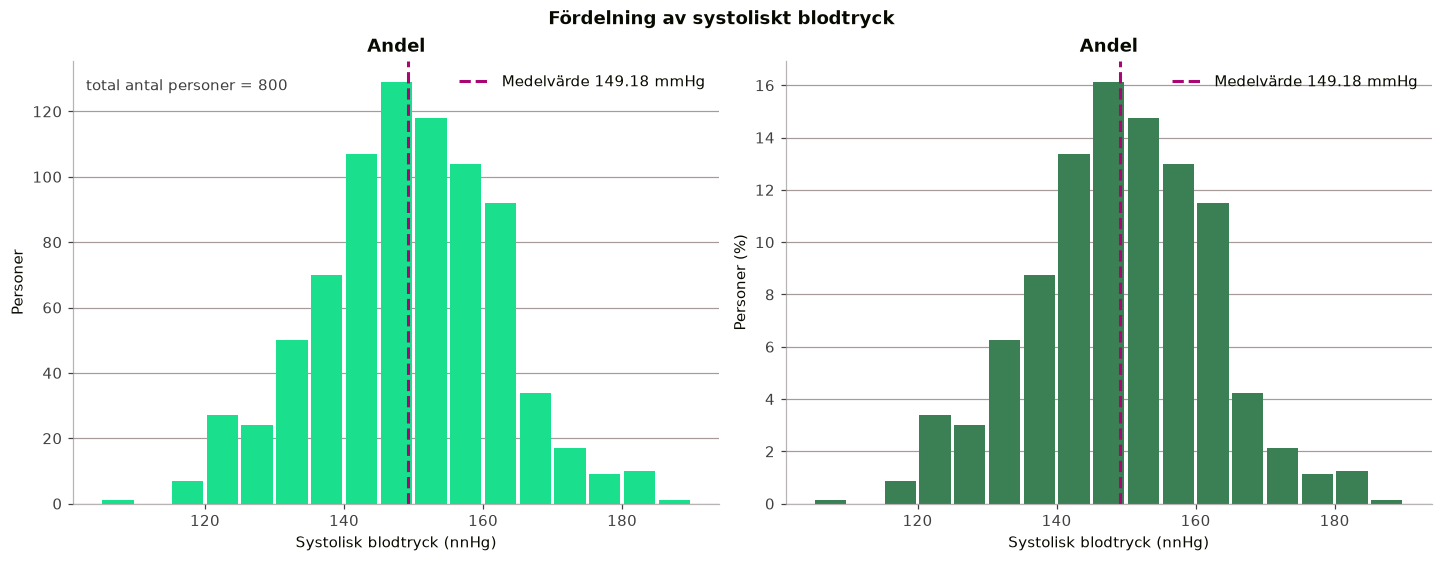

In [183]:

bp_bin_width = 5
bp_bins = np.arange(
    np.floor(bp_values.min() / bp_bin_width) * bp_bin_width,
    np.ceil(bp_values.max() / bp_bin_width) * bp_bin_width + bp_bin_width,
    bp_bin_width,
)

bp_hist_counts, _ = np.histogram(bp_values, bins=bp_bins)
bp_hist_percent = bp_hist_counts / bp_count * 100
bp_bin_centers = (bp_bins[:-1] + bp_bins[1:]) / 2

fig_bp, axes_bp = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for axis, values, color, subtitle, ylabel in [
    (axes_bp[0], bp_hist_counts, COLORS["blood_pressure"], "Andel", "Personer"),
    (axes_bp[1], bp_hist_percent, COLORS["blood_pressure_light"], "Andel", "Personer (%)"),
]:
    axis.bar(bp_bin_centers, values, width=bp_bin_width * 0.90, color=color)
    axis.axvline(bp_mean, color=COLORS["reference"], linestyle="--", linewidth=2, label=f"Medelvärde {bp_mean:.2f} mmHg")
    axis.set(title=subtitle, xlabel="Systolisk blodtryck (nnHg)", ylabel=ylabel)
    axis.legend(loc="upper right")
    style_axis(axis)
axes_bp[0].text(0.02, 0.96, f"total antal personer = {bp_count}", transform=axes_bp[0].transAxes, va="top", color=COLORS["muted"])
fig_bp.suptitle("Fördelning av systoliskt blodtryck", fontweight="bold")
plt.show()


#### 3.2.2 viktfördelning efter kön

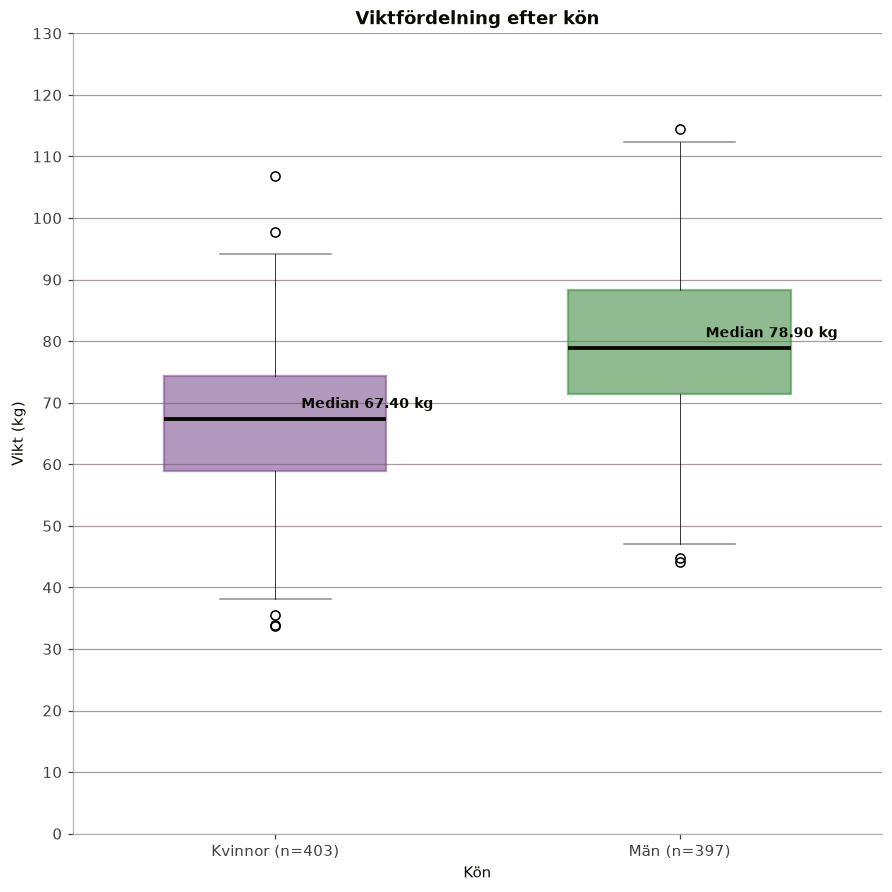

In [184]:
median_weight_by_sex = df.groupby("sex")["weight"].median()
weight_groups = [df.loc[df["sex"] == sex, "weight"].dropna() for sex in SEX_COLUMN]
weight_labels = [f"{label} (n={len(values)})" for label, values in zip(["Kvinnor", "Män"], weight_groups)]



fig_weight, ax_weight = plt.subplots(figsize=(8, 8), layout="constrained")
weight_box = ax_weight.boxplot(
    weight_groups, patch_artist=True, tick_labels=weight_labels, widths=0.55,
    medianprops={"color": COLORS["ink"], "linewidth":2.5},
    whiskerprops={"linewidth":0.5},
    capprops={"marker": None, "markersize":7, "alpha":0.45, "markeredgecolor": COLORS["muted"]},
)
for patch, sex in zip(weight_box["boxes"], SEX_COLUMN):
    patch.set(facecolor=SEX_colors[sex], alpha=0.6, edgecolor=SEX_colors[sex], linewidth=1.5)
for pos, sex in enumerate(SEX_COLUMN, start=1):
    median = median_weight_by_sex.loc[sex]
    ax_weight.annotate(f"Median {median:.2f} kg", (pos, median),
                       xytext=(17, 7), textcoords="offset points", fontsize=9,
                       color=COLORS["ink"], fontweight="bold")
ax_weight.set(title="Viktfördelning efter kön", xlabel="Kön", ylabel="Vikt (kg)")
style_axis(ax_weight)

ax_weight.set_yticks(range(0, 131, 10))
plt.show()

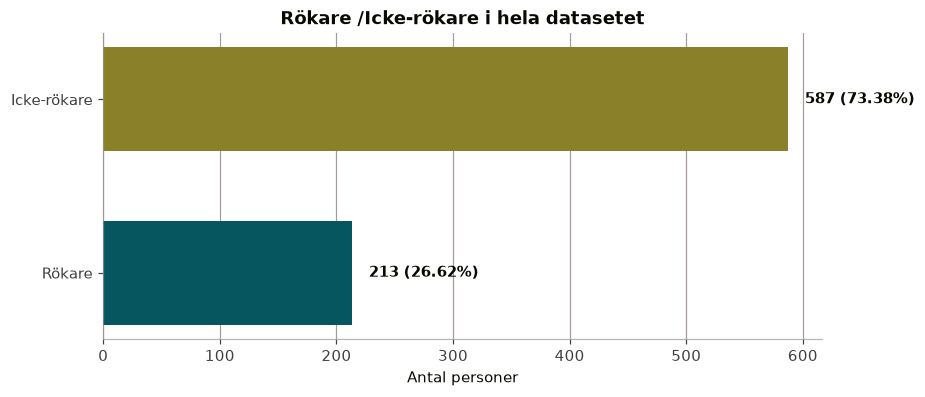

In [185]:
smoking_counts = pd.crosstab(df["sex"], df["smoker"]).reindex(
    index=SEX_COLUMN, columns=SMOKER_COLUMN, fill_value=0
)
smoking_perc = smoking_counts.div(smoking_counts.sum(axis=1), axis=0) * 100
smoking_all_counts = smoking_counts.sum(axis=0)

fig_smoking, ax_smoking = plt.subplots(figsize=(8.3, 3.5), layout="constrained")
smoking_labels = {"No": "Icke-rökare", "Yes": "Rökare"}

for idx, status in enumerate(SMOKER_COLUMN):
    count = int(smoking_all_counts.loc[status])
    ax_smoking.barh(idx, count, color=SMOKING_COLORS[status], height=0.6)
    ax_smoking.text(count + max(smoking_all_counts) * 0.025, idx,
                    f"{count} ({count / smoking_all_counts.sum():.2%})",
                    va="center", fontweight="bold")
ax_smoking.set_yticks(range(len(SMOKER_COLUMN)),[smoking_labels[status] for status in SMOKER_COLUMN])
ax_smoking.invert_yaxis()
ax_smoking.set(title="Rökare /Icke-rökare i hela datasetet", xlabel="Antal personer")
style_axis(ax_smoking, grid_axis="x")
plt.show()

In [186]:
display(smoking_counts.rename(
    index={"F": "Kvinnor", "M": "Män"},
    columns={"No": "Icke-rökare", "Yes":"Rökare"}))

smoker,Icke-rökare,Rökare
sex,,
Kvinnor,287,116
Män,300,97


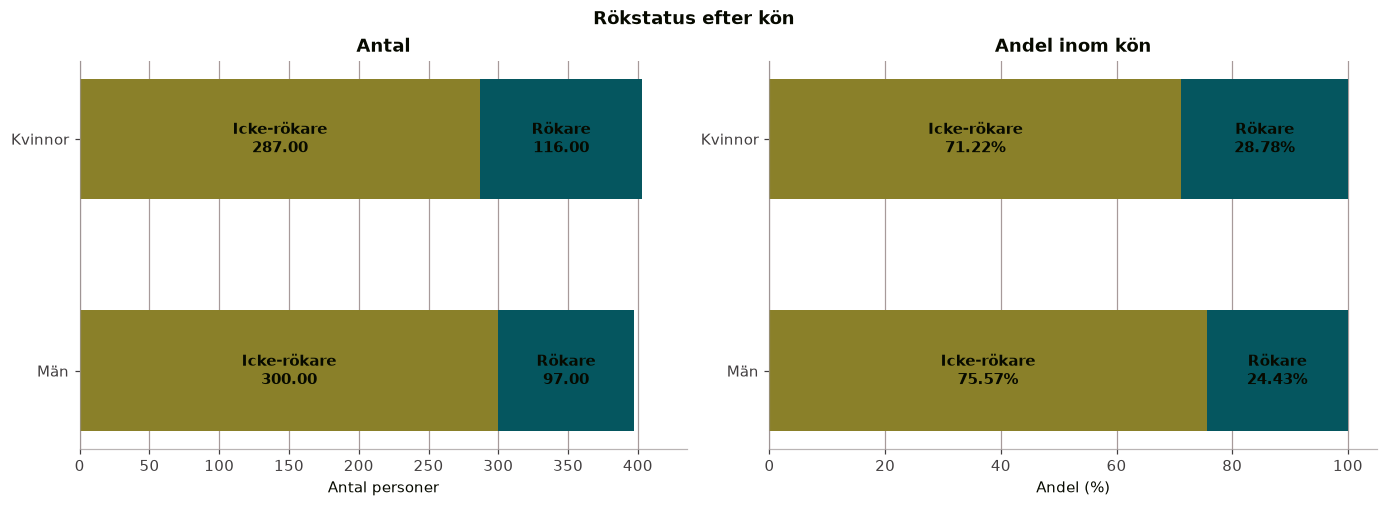

In [187]:
fig_smoking_sex, axes_smoking_sex = plt.subplots(
    1, 2, figsize=(12.5, 4.5), layout="constrained"
)
sex_names = ["Kvinnor", "Män"]
sex_positions = np.arange(len(SEX_COLUMN))
for axis, table, subtitle, xlabel, is_percent in [
    (axes_smoking_sex[0], smoking_counts, "Antal", "Antal personer", False),
    (axes_smoking_sex[1], smoking_perc, "Andel inom kön", "Andel (%)", True),
]:
    left = np.zeros(len(SEX_COLUMN))
    for status in SMOKER_COLUMN:
        widths = table[status].to_numpy()
        bars = axis.barh(sex_positions, widths, left=left, height=0.52,
                         label=smoking_labels[status], color=SMOKING_COLORS[status])
        for bar, value in zip(bars, widths):
            axis.text(bar.get_x() + bar.get_width() / 2,
                          bar.get_y() + bar.get_height() / 2,
                          (f"{smoking_labels[status]}\n{value:.2f}%" if is_percent
                           else f"{smoking_labels[status]}\n{value:.2f}"),
                          ha="center", va="center", color=COLORS["ink"], fontweight="bold", fontsize=10)
        left += widths
    axis.set_yticks(sex_positions, sex_names)
    axis.invert_yaxis()
    axis.set(title=subtitle, xlabel=xlabel)
    axis.set_xlim(0, 105 if is_percent else float(table.sum(axis=1).max()) * 1.08)
    style_axis(axis, grid_axis="x")
# Gruppnamnen är utskrivna i procentstaplarna, så ingen legend täcker figuren.
fig_smoking_sex.suptitle("Rökstatus efter kön", fontweight="bold")
plt.show()

## 4. Simulering kopplad till caset

### 4.1 Andelen personer i datasetet som har sjukdom

 I analysen antar vi att:
 disease = 0 betyder att personen har inte sjukdom och disease = 1 betyder att personen har sjukdomen.

In [188]:
disease_rate = df["disease"].mean()

print(f"Andel personer med sjukdom:  {disease_rate:.4%}")

Andel personer med sjukdom:  5.8750%


Andel personer med sjukdom 5,875%.

### 4.2 Ny grupp med 1 000 slumpade personer

In [189]:
rng_disease = np.random.default_rng(RANDOM_SEED)
simulated_objects = rng_disease.binomial(1, disease_rate, size=SIM_GROUP_SIZE)
simulated_yes_group = simulated_objects.mean()

print(f"Simulerad andel med sjuktom: {simulated_yes_group:.2%}")

Simulerad andel med sjuktom: 5.40%


### 4.3 Jämförelse

In [190]:
print(f" Andel personer med sjukdom i databaset:  {disease_rate:.4%}")
print(f" Simulerad andel med sjuktom:             {simulated_yes_group:.4%}")
print(f" Skillnad:                               {simulated_yes_group - disease_rate:.4%}")

 Andel personer med sjukdom i databaset:  5.8750%
 Simulerad andel med sjuktom:             5.4000%
 Skillnad:                               -0.4750%


## 5. Konfidensintervall - normalapproximation

Värdena beräknades i avsnitt 1.

In [191]:
results = pd.DataFrame({
    "Statistika": ["Medelvärde:",
                   "Standartavvikelse:",
                   "Antal observationer:",
                   "Standardfel:"
                       ],
    "Värde": [
        f"{bp_mean:.4f} mmHg",
        f"{bp_std:.4f} mmHg",
        str(bp_count),
        f"{bp_se:.4f} mmHg"
                       ]
})

display(results.style.hide(axis="index"))

Statistika,Värde
Medelvärde:,149.1786 mmHg
Standartavvikelse:,12.7934 mmHg
Antal observationer:,800
Standardfel:,0.4523 mmHg


### 5.2 Konfidensintervall - felmarginal, gränser

In [192]:
normal_margin = stats.norm.ppf(1 - ALPHA / 2) * bp_se
normal_ci = (bp_mean -normal_margin, bp_mean + normal_margin) 
print(f"Felmarginal: {normal_margin:.4f} mmHg")
print(f"95% konfidensintervall, normalapproximation: [{normal_ci[0]:.4f}, {normal_ci[1]:.4f}] mmHg")

Felmarginal: 0.8865 mmHg
95% konfidensintervall, normalapproximation: [148.2921, 150.0651] mmHg


## 6. Konfidensintervall - boostrap

In [193]:
rng_bootrap =np.random.default_rng(RANDOM_SEED)
bp_array = bp_values.to_numpy()
bootstrap_means= np.empty(N_BOOTSTRAP, dtype=float)
bootstrap_batch_size = 2000
for batch_start in range(0, N_BOOTSTRAP, bootstrap_batch_size):
    batch_end = min(batch_start + bootstrap_batch_size, N_BOOTSTRAP)
    samples = rng_bootrap.choice(bp_array, size=(batch_end - batch_start, bp_count), replace=True)
    bootstrap_means[batch_start:batch_end] = samples.mean(axis=1)


print("Boostrapreplikat:" ,len(bootstrap_means))
display(bootstrap_means[:5])


Boostrapreplikat: 50000


array([149.59025 , 148.946875, 149.305625, 149.211625, 150.29225 ])

### 6.1 Bootstrapintervallets gränser

In [194]:
bootstrap_ci = tuple(np.percentile(bootstrap_means, [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]))
print(f"95% CI, bootstrap: [{bootstrap_ci[0]:.4f}, {bootstrap_ci[1]:.4f}] mmHg")

95% CI, bootstrap: [148.2905, 150.0691] mmHg


### 6.2 Stability när antalet bootstrapreplikat ökar

In [195]:

bootstrap_check_sizes = list(range(BOOTSTRAP_START, N_BOOTSTRAP, BOOTSTRAP_STEP))
if not bootstrap_check_sizes or bootstrap_check_sizes[-1] != N_BOOTSTRAP:
    bootstrap_check_sizes.append(N_BOOTSTRAP)
bootstrap_lower_bounds = []
bootstrap_upper_bounds = []
bootstrap_ci_changes = []
previous_ci = None
for n_replicates in bootstrap_check_sizes:
    current_ci = tuple(np.percentile(bootstrap_means[:n_replicates],
                                    [100 * ALPHA / 2, 100 * (1 - ALPHA / 2)]))
    bootstrap_lower_bounds.append(current_ci[0])
    bootstrap_upper_bounds.append(current_ci[1])
    if previous_ci is not None:
        bootstrap_ci_changes.append(max(abs(current_ci[0] - previous_ci[0]),
                                        abs(current_ci[1] - previous_ci[1])))
    previous_ci = current_ci
   

### 5.1 boostrap - gränser

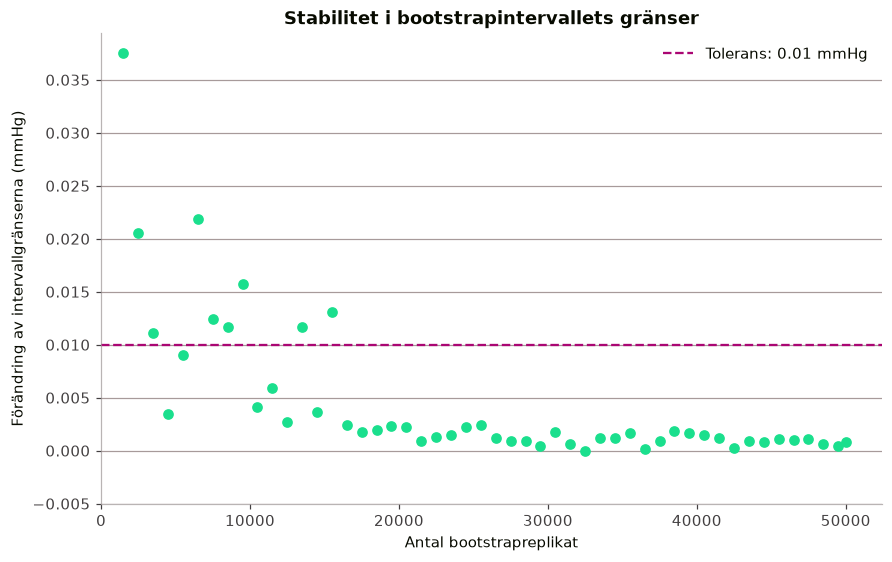

In [196]:
fig_bootstrap_stability, ax_bootstrap_stability = plt.subplots(
    figsize=(8, 5),
    layout="constrained"
)

ax_bootstrap_stability.scatter(
    bootstrap_check_sizes[1:],
    bootstrap_ci_changes,
    color=COLORS["blood_pressure"]
)

ax_bootstrap_stability.axhline(
    0.01,
    color=COLORS["reference"],
    linestyle="--",
    label="Tolerans: 0.01 mmHg"
)

ax_bootstrap_stability.set(
    title="Stabilitet i bootstrapintervallets gränser",
    xlabel="Antal bootstrapreplikat",
    ylabel="Förändring av intervallgränserna (mmHg)"
)

ax_bootstrap_stability.set_ylim(bottom=-0.005)
ax_bootstrap_stability.set_xlim(left=0)
ax_bootstrap_stability.legend()

style_axis(ax_bootstrap_stability)

plt.show()

### 6.4 Jämförelse mellan metoderna

In [197]:
ci_table = pd.DataFrame({
    "Metod": ["Normalapproximation", "Bootstrap"],
    "Nedre gräns (mmHG)": [normal_ci[0], bootstrap_ci[0]],
    "Över gräns (mmHg)":  [normal_ci[1], bootstrap_ci[1]]
})

display(ci_table.round(4).style.hide(axis="index"))

Metod,Nedre gräns (mmHG),Över gräns (mmHg)
Normalapproximation,148.292100,150.065100
Bootstrap,148.290500,150.069100


## 7. Hypotesprövning

### Påstående :" Rökare har högre medelblodtryck än icke-rökare."

### 6.1 formulera hypoteser

H0: Rökare har inte högre medelblodtryck än icke-rökare. 
H1: Rökare har högre medelblodtryck än icke-rökare.

### 6.2 signifikansnivå

In [198]:
alpha = 0.05

### 6.3 Data

In [199]:
smoker_bp = df[df["smoker"] == "Yes"]["systolic_bp"].dropna()
no_smoker_bp = df[df["smoker"] == "No"]["systolic_bp"].dropna()

smoker_n, non_smoker_n = len(smoker_bp), len(no_smoker_bp)
smoker_mean, non_smoker_mean = smoker_bp.mean(), no_smoker_bp.mean()
smoker_std, non_smoker_std = smoker_bp.std(ddof=1), no_smoker_bp.std(ddof=1)
smoker_fraction = smoker_n / (smoker_n + non_smoker_n)

smoker_no_smoker_summary = pd.DataFrame({
    "Grupp": ["Rökare", "Icke-rökare"],
    "Antal": [smoker_n, non_smoker_n],
    "medeltryck (mmHg)": [smoker_mean, non_smoker_mean],
    "Standartavvikelse": [smoker_std, non_smoker_std]
})

display(smoker_no_smoker_summary.round(4).style.hide(axis="index"))

Grupp,Antal,medeltryck (mmHg),Standartavvikelse
Rökare,213,149.524900,13.267800
Icke-rökare,587,149.053000,12.626000


### 7.4 T-test  - Welch

In [200]:
welch_ttest = stats.ttest_ind(smoker_bp, no_smoker_bp, equal_var=False, alternative="greater")
print(f"Welch t-statistik: {welch_ttest.statistic:.4f}")
print(f"Welch p-värde:     {welch_ttest.pvalue:.4f}")
print("\nReslutat: H0" , "förkastas." if welch_ttest.pvalue  < ALPHA  else "förkastas inte." )

Welch t-statistik: 0.4503
Welch p-värde:     0.3264

Reslutat: H0 förkastas inte.


## 8. Power-analys genom simulering

In [202]:
rng_power = np.random.default_rng(RANDOM_SEED)
power_rows = []
power_batch_size = 250

for total_n in POWER_SAMPLE_SIZE:
    simulated_smoker_n = round(total_n * smoker_fraction)
    simulated_non_smoker_n = total_n - simulated_smoker_n
    welch_significant = 0

    for batch_start in range(0, N_POWER_SIM, power_batch_size):
        batch_n = min(power_batch_size, N_POWER_SIM - batch_start)
        sim_smoker_power =rng_power.normal(
            smoker_mean, smoker_std, size=(batch_n, simulated_smoker_n)
        )
        sim_no_smoker_power =rng_power.normal(
            non_smoker_mean, non_smoker_std, size=(batch_n, simulated_non_smoker_n)
        )
        wech_p = stats.ttest_ind(
            sim_smoker_power, sim_no_smoker_power, axis=1, equal_var=False, alternative="greater"
        ).pvalue
        welch_significant += np.count_nonzero(wech_p < ALPHA)

    power_rows.append({
        "Total antal:": total_n,
        "Simulation - antal rökare:": simulated_smoker_n,
        "Simulation - antal icke-rökare:": simulated_non_smoker_n,
        "Welch power:": welch_significant / N_POWER_SIM,
    })

power_results = pd.DataFrame(power_rows)
display(power_results.round(4).style.apply(
    lambda row: ["background-color: red; color: white"] * len(row) if row.name == 3 else[""] * len(row), axis=1))

,Total antal:,Simulation - antal rökare:,Simulation - antal icke-rökare:,Welch power:
0,100,27,73,0.067400
1,200,53,147,0.074800
2,400,106,294,0.092800
3,800,213,587,0.118500
4,1600,426,1174,0.151700
5,3200,852,2348,0.230500


SLUSTATS